# Intelligent Financial Research & Analysis Platform

This notebook demonstrates the end-to-end workflow:
1. **News Sentiment Analysis** (VADER NLP)
2. **Stock Data & Technical Indicators** (yfinance, MA20, Bollinger Bands)
3. **Predictive Modeling** (Random Forest Regression & PyTorch LSTM on CUDA GPU)
4. **Performance Evaluation & Metrics** (RMSE, MAE, R2)
5. **Final Research Verdict** (Integrated Summary & Recommendation)

### Step 1: Install Dependencies & Setup Environment

In [1]:
import warnings
warnings.filterwarnings("ignore")

import torch
import nltk
nltk.download("vader_lexicon", quiet=True)

import config
from data.stock_data import fetch_raw_data, engineer_features, train_test_split_df
from analysis.technical import plot_moving_average, plot_bollinger_bands, print_trend_summary
from analysis.sentiment import fetch_headlines, analyze_sentiment, print_sentiment_report, plot_sentiment_distribution
from models.random_forest import train_random_forest, plot_feature_importance
from models.lstm_model import prepare_lstm_data, train_lstm, predict_lstm, plot_training_loss, DEVICE
from evaluation.compare_models import compute_metrics, print_comparison_table, plot_comparison, print_final_verdict, plot_metrics_bar

gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'None (CPU)'
print("All modules imported successfully!")
print(f"PyTorch Device: {DEVICE} | GPU Detected: {gpu_name}")

All modules imported successfully!
PyTorch Device: cuda | GPU Detected: NVIDIA GeForce RTX 4050 Laptop GPU


### Step 2: Choose Stock to Analyze (150 Stocks Across Sensex, Nifty 50, and Nasdaq-100)
Select any stock by number (`1` to `150`), by index filter, or by typing ticker symbol directly.


In [2]:
# ==============================================================================
# 150 MULTI-MARKET STOCK UNIVERSE: BSE Sensex, NSE Nifty 50, and Nasdaq-100
# ==============================================================================
# Quick Index Reference:
#   BSE Sensex   : Options 1 - 30   (e.g., 1: HDFC Bank, 8: Reliance, 12: TCS)
#   NSE Nifty 50 : Options 1 - 50   (e.g., 31: Tata Motors, 34: Cipla, 41: ONGC)
#   Nasdaq-100   : Options 51 - 150 (e.g., 51: NVDA, 52: AAPL, 54: AMZN, 58: TSLA)
# ==============================================================================

# Helper: list and search stocks across the 150 options
def list_stocks(index=None, search=None):
    """Filter stocks by index ('Sensex', 'Nifty', 'Nasdaq') or search keyword."""
    print(f"\n{'='*65}")
    print(f"  AVAILABLE STOCKS UNIVERSE (Total: {len(config.STOCK_OPTIONS)})")
    print(f"{'='*65}")
    count = 0
    for k, (t, c, cat) in config.STOCK_OPTIONS.items():
        if index and index.lower() not in cat.lower():
            continue
        if search and (search.lower() not in t.lower() and search.lower() not in c.lower()):
            continue
        print(f"  [{k:>3}] {t:<15} - {c:<30} [{cat}]")
        count += 1
    print(f"{'='*65}")
    print(f"  Showing {count} matching stocks.\n")

# Choose your stock here: pick number (1-150) or type custom ticker
PICK = "58"  # Examples: '12' -> TCS.NS | '51' -> NVDA | '58' -> TSLA | '52' -> AAPL

if PICK in config.STOCK_OPTIONS:
    TICKER, COMPANY_NAME, INDEX_CAT = config.STOCK_OPTIONS[PICK]
else:
    TICKER = "TSLA"
    COMPANY_NAME = "Tesla"
    INDEX_CAT = "Nasdaq-100"

print(f"Selected: [{PICK}] {TICKER} - {COMPANY_NAME} [{INDEX_CAT}]")
print("Tip: Run `list_stocks('Sensex')`, `list_stocks('Nifty')`, or `list_stocks('Nasdaq')` to browse.")


Selected: [58] TSLA - Tesla [Nasdaq-100]
Tip: Run `list_stocks('Sensex')`, `list_stocks('Nifty')`, or `list_stocks('Nasdaq')` to browse.


### Step 3: News Sentiment Analysis (VADER NLP)

  * 10 live headlines fetched from NewsAPI for 'Tesla stock'.

------------------------------------------------------------
  News Sentiment Analysis Report
------------------------------------------------------------
  [~] [Neutral ] (+0.000)  Going global: Step-by-step guide to buying international stocks
  [~] [Neutral ] (+0.000)  TSLA Stock Is October’s Mag 7 King — But 2 Motorcycle Stocks Race Past Tesla Even As Chinese EV Stocks See Red
  [~] [Neutral ] (+0.000)  Global stock markets rise as investors continue to bet on AI
  [~] [Neutral ] (+0.000)  Global stock markets rise as investors continue to bet on AI
  [~] [Neutral ] (-0.026)  Tesla Stock Rises In A Buy Range; Musk Touts Cybercab Fleet Expansion
  [~] [Neutral ] (+0.000)  X Layer adds $32 million in tokenized stock market cap in one week
  [+] [Positive] (+0.784)  Tech firms gain on Anthropic IPO optimism, Microsoft exit package for 60,000 staff
  [+] [Positive] (+0.340)  NYSE bets on all-or-nothing options as event driv

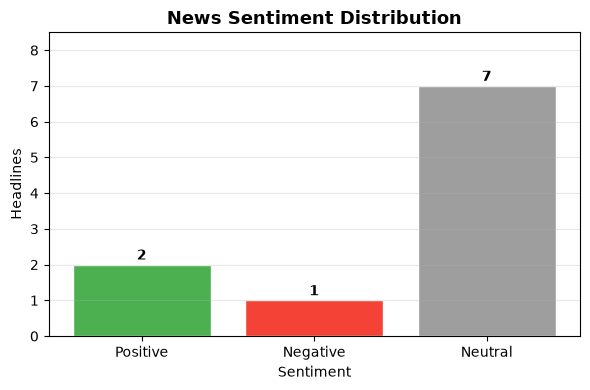

In [3]:
headlines = fetch_headlines(query=COMPANY_NAME)
results, sentiment_score = analyze_sentiment(headlines)
print_sentiment_report(results, sentiment_score)
plot_sentiment_distribution(results)

### Step 4: Download Stock Data & Technical Analysis

  -> Downloading TSLA (2y)... (attempt 1)
     501 days loaded (2024-10-29 to 2026-10-28)
     Train: 385 rows | Test: 97 rows

──────────────────────────────────────────────────
  TSLA | Close: 404.22 | MA20: 376.78 | +7.28%
  BULLISH -- price is above its average.
──────────────────────────────────────────────────



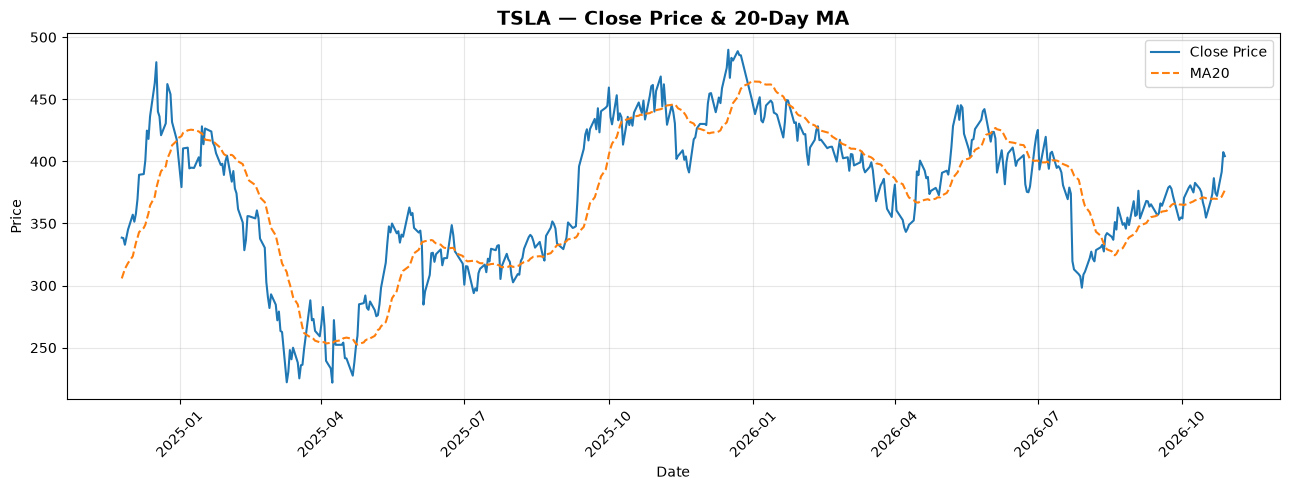

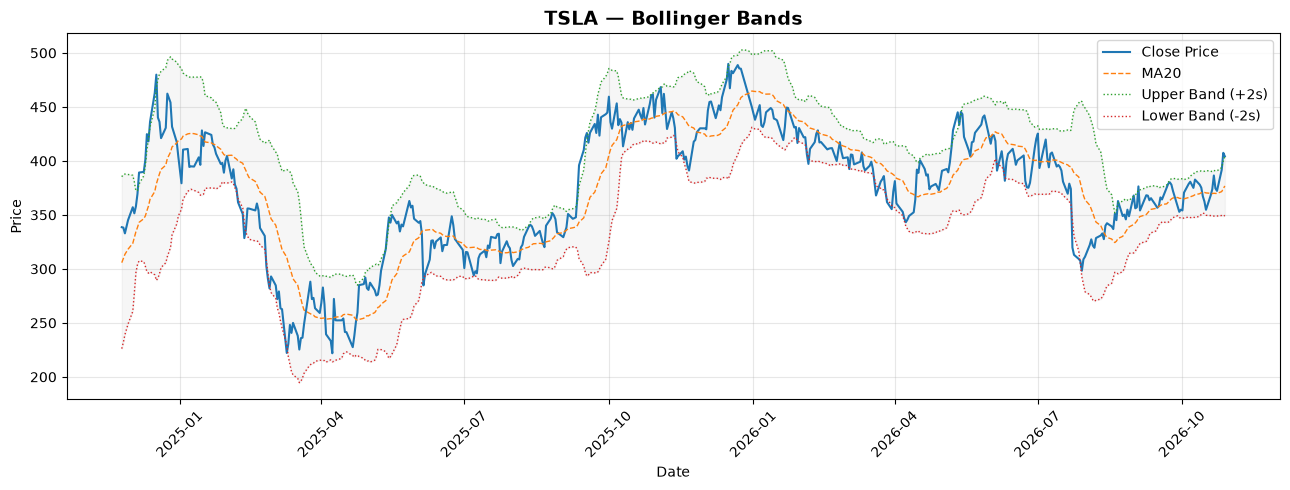

In [4]:
raw_df = fetch_raw_data(ticker=TICKER)
df = engineer_features(raw_df, sentiment_score=sentiment_score)
X_train, X_test, y_train, y_test, test_dates = train_test_split_df(df)

print_trend_summary(df, ticker=TICKER)
plot_moving_average(df, ticker=TICKER)
plot_bollinger_bands(df, ticker=TICKER)

### Step 5: Model 1 — Random Forest Regression

  -> Training Random Forest...
     Done. (200 trees)


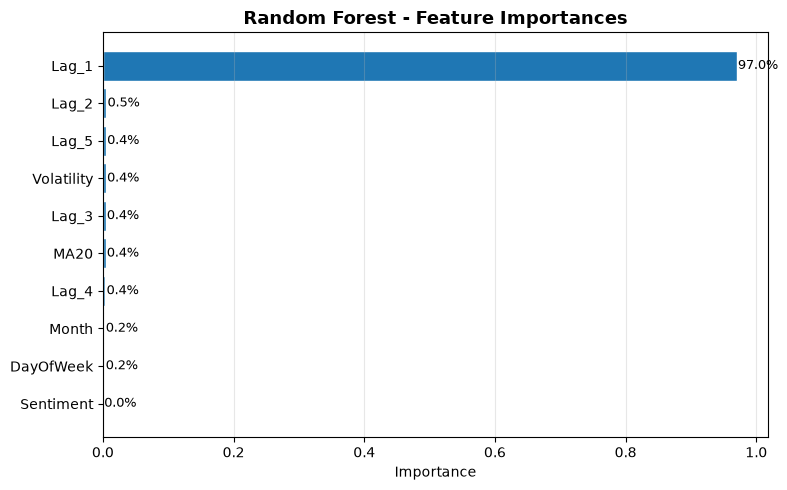

In [5]:
rf_model = train_random_forest(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
plot_feature_importance(rf_model)

### Step 6: Model 2 — LSTM Neural Network (CUDA Accelerated)

  -> Training LSTM on [CUDA: NVIDIA GeForce RTX 4050 Laptop GPU]...
     Done. 38 epochs | val_loss=0.034919


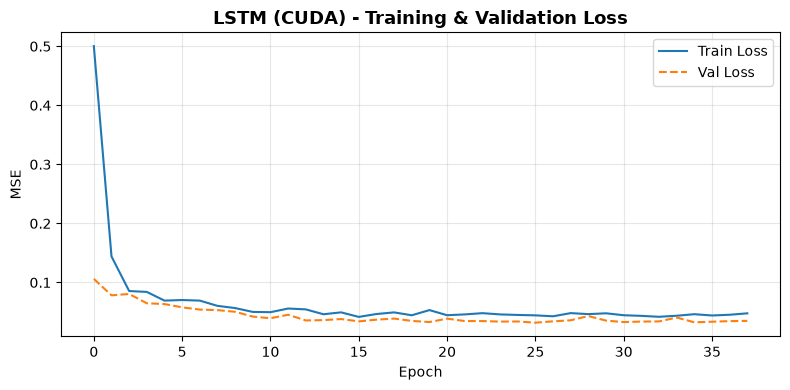

In [6]:
X_tr_s, X_te_s, y_tr_s, scaler_y = prepare_lstm_data(X_train, y_train, X_test)
lstm_model, history = train_lstm(X_tr_s, y_tr_s)
y_pred_lstm = predict_lstm(lstm_model, X_te_s, scaler_y)

plot_training_loss(history)

### Step 7: Model Comparison, Evaluation & Final Verdict


   Model Performance Comparison
  Metric        Random Forest             LSTM
----------------------------------------------------
  RMSE              13.65 USD        12.30 USD   LSTM *
  MAE                9.76 USD         9.19 USD   LSTM *
  R2                   0.7723           0.8152   LSTM *
  RMSE & MAE -> lower is better (USD) | R2 -> higher is better (max 1.0)



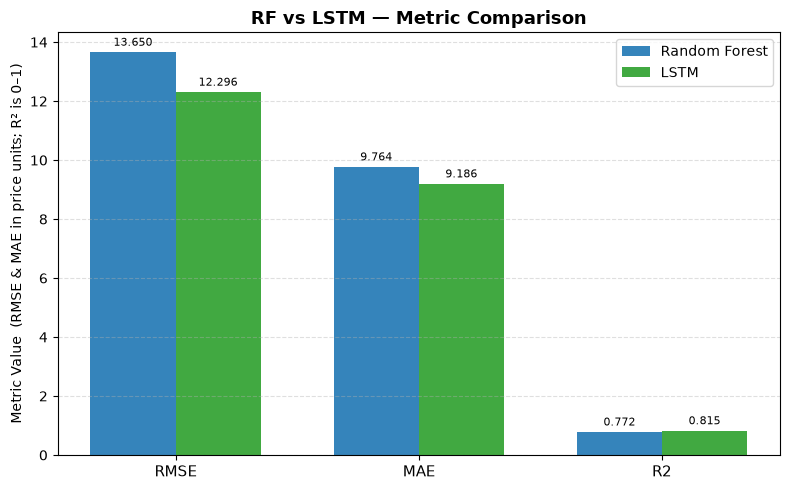

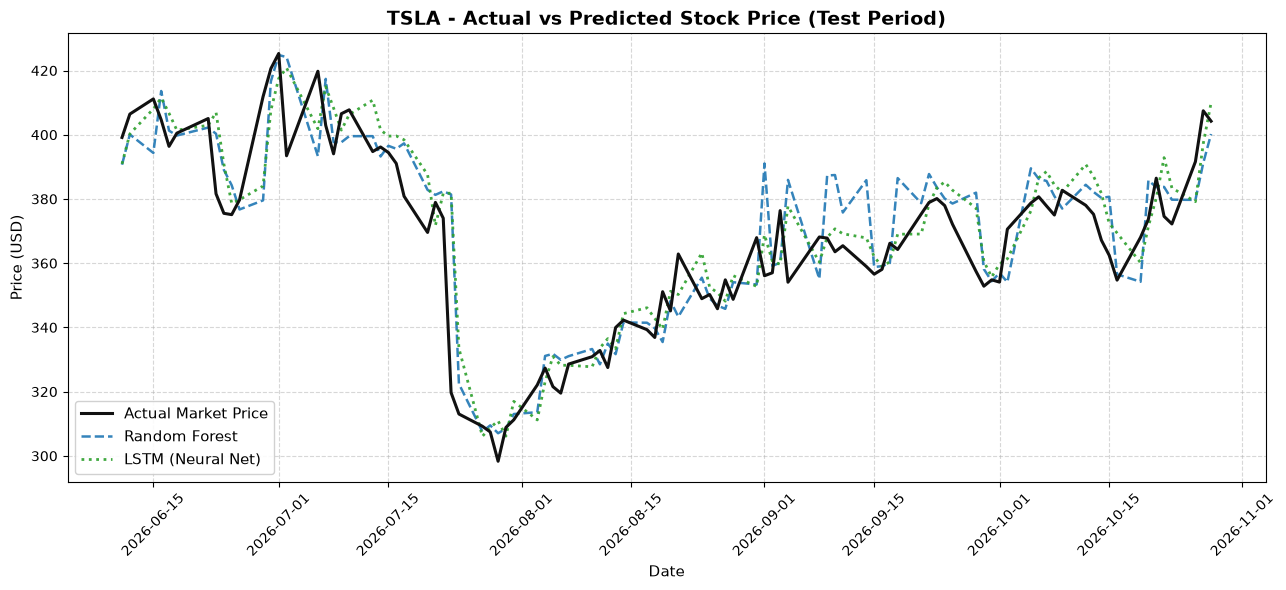


                     RESEARCH SUMMARY & FINAL DEDUCTION

[TECHNICALS]
  * ABOVE 20-Day MA (Bullish) | Current: USD 404.22 vs MA20: USD 376.78 (+7.28%)

[NEWS SENTIMENT]
  * POSITIVE (Compound Score: +0.078)

[MACHINE LEARNING]
  * Superior Model: LSTM (R2 = 0.8152)
    * RF R2: 0.7723 | RMSE: USD 13.65
    * LSTM R2: 0.8152 | RMSE: USD 12.30
    * Projected Move: UPWARD (+1.42% expected)

----------------------------------------------------------------------
FINAL CONCLUSION & DEDUCTION:
  "The analysis presents a strong Bullish outlook for TSLA. Both news sentiment and technical trend are positive (price above 20-day MA). LSTM delivered the higher predictive accuracy (R2 = 0.8152) and forecasts continued UPWARD momentum."



In [7]:
from evaluation.compare_models import compute_metrics, print_comparison_table, plot_comparison, plot_metrics_bar
# Align lengths: LSTM output is shorter than RF due to the lookback window.
n_lstm      = len(y_pred_lstm)
y_test_lstm = y_test[-n_lstm:]      # portion of y_test that maps to LSTM predictions
lstm_dates  = test_dates[-n_lstm:]  # corresponding dates

rf_metrics   = compute_metrics(y_test,      y_pred_rf)
lstm_metrics = compute_metrics(y_test_lstm, y_pred_lstm)

# 1. Performance Metrics Table (Dynamic currency: Rs for Sensex/Nifty, USD for Nasdaq)
print_comparison_table(rf_metrics, lstm_metrics, ticker=TICKER)

# 2. Metric Comparison Bar Chart
plot_metrics_bar(rf_metrics, lstm_metrics)

# 3. Actual vs Predicted Chart
# (Automatically prints the Three-Pillar Research Summary & Final Deduction right after the plot)
plot_comparison(lstm_dates, y_test_lstm, y_pred_rf, y_pred_lstm, ticker=TICKER)
